# code_110 · Irregular sequences, gates and state boundaries

**Book:** section 22.3. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_22_GUIDE.md), [run evidence](../CHAPTER_22_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_110).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2310;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2310


<a id="state-contract"></a>
 ## State follows an episode, not a row counter
 Generate one irregular maintenance episode for each of fifty buildings, split 30/10/10 by entire building. Episode lengths are 24–40 events. Elapsed times, admitted readings and observation indicators are inputs; a known decaying generator state supplies teaching targets. Missing readings are recorded as zero with a separate observation indicator. Right-padding has a separate validity mask. Ten independent longer episodes (80–96 events) from the final building IDs assess a further length shift; they reset the generator state and supply no fitting evidence. Compare native RNN, GRU and LSTM full-history training with a GRU whose derivative history is detached every eight events. All get 120 optimizer updates and development-only checkpoint selection.


,model,best_update,development_MSE,final_source_length_MSE,final_long_episode_MSE,parameters
0,RNN,115,0.001389,0.001067,0.004850,113
1,GRU,120,0.000297,0.000243,0.001395,321
2,LSTM,110,0.000517,0.000455,0.002001,425
3,Truncated GRU,120,0.000262,0.000252,0.001431,321


Full / detached first-event gradients: 0.00044550543286659913 0.0


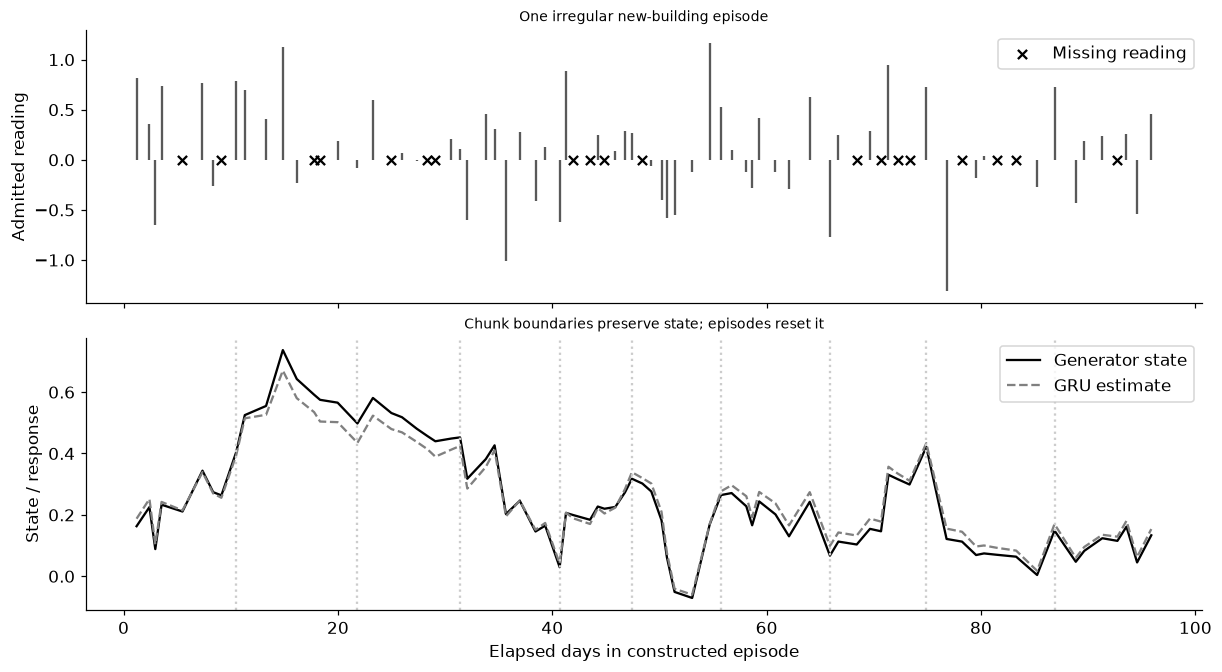

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
def episodes(count,minimum,maximum):
    lengths=rng.integers(minimum,maximum+1,count);width=maximum;raw=np.zeros((count,width,3));target=np.zeros((count,width));valid=np.arange(width)[None,:]<lengths[:,None]
    for i,length in enumerate(lengths):
        dt=rng.uniform(.5,2.,length);observed=rng.random(length)<.8;reading=rng.normal(0,.5,length);state=0.
        for step in range(length):
            state=.95**dt[step]*state+.2*reading[step]*observed[step];raw[i,step]=[reading[step]*observed[step],dt[step],observed[step]];target[i,step]=state
    return raw,target,valid,lengths
raw,target,valid,lengths=episodes(50,24,40);long_raw,long_target,long_valid,long_lengths=episodes(10,80,96);scaler=StandardScaler().fit(raw[:30][valid[:30]])
x=torch.tensor(scaler.transform(raw.reshape(-1,3)).reshape(raw.shape));y=torch.tensor(target);mask=torch.tensor(valid);long_x=torch.tensor(scaler.transform(long_raw.reshape(-1,3)).reshape(long_raw.shape));long_y=torch.tensor(long_target);long_mask=torch.tensor(long_valid)
assert x.shape==(50,40,3) and not set(range(30))&set(range(40,50))
class RecurrentModel(nn.Module):
    def __init__(self,kind):
        super().__init__();self.recurrent={'RNN':nn.RNN,'GRU':nn.GRU,'LSTM':nn.LSTM}[kind](3,8,batch_first=True,dropout=0.,bidirectional=False);self.head=nn.Linear(8,1)
    def forward(self,values,state=None):
        output,state=self.recurrent(values,state);return self.head(output).squeeze(-1),state
def detach_state(state):return tuple(value.detach() for value in state) if isinstance(state,tuple) else state.detach()
configurations=[('RNN','RNN',False),('GRU','GRU',False),('LSTM','LSTM',False),('Truncated GRU','GRU',True)];fitted={};rows=[];histories={}
for name,kind,truncated in configurations:
    torch.manual_seed(SEED);model=RecurrentModel(kind);optimizer=torch.optim.AdamW(model.parameters(),lr=.01,weight_decay=.001);best=float('inf');best_state=None;history=[]
    for iteration in range(120):
        optimizer.zero_grad();model.train()
        if truncated:
            state=None;total=mask[:30].sum()
            for start in range(0,40,8):
                prediction,state=model(x[:30,start:start+8],state);loss=(((prediction-y[:30,start:start+8])**2)*mask[:30,start:start+8]).sum()/total;loss.backward();state=detach_state(state)
        else:
            prediction,state=model(x[:30]);loss=(((prediction-y[:30])**2)*mask[:30]).sum()/mask[:30].sum();loss.backward()
        optimizer.step()
        if (iteration+1)%5==0:
            model.eval()
            with torch.no_grad():prediction,_=model(x[30:40]);value=float((((prediction-y[30:40])**2)*mask[30:40]).sum()/mask[30:40].sum())
            history.append({'optimizer_update':iteration+1,'development_MSE':value})
            if value<best:best=value;best_state=copy.deepcopy(model.state_dict());best_update=iteration+1
    model.load_state_dict(best_state);model.eval()
    with torch.no_grad():
        prediction,_=model(x[40:]);long_prediction,_=model(long_x);short_mse=float((((prediction-y[40:])**2)*mask[40:]).sum()/mask[40:].sum());long_mse=float((((long_prediction-long_y)**2)*long_mask).sum()/long_mask.sum())
    rows.append({'model':name,'best_update':best_update,'development_MSE':best,'final_source_length_MSE':short_mse,'final_long_episode_MSE':long_mse,'parameters':sum(p.numel() for p in model.parameters())});fitted[name]=model;histories[name]=history
# Native gate conventions are checked on the first valid event, not guessed from another implementation.
gru=fitted['GRU'].recurrent;first=long_x[:1,:1];zero=torch.zeros(1,8)
with torch.no_grad():
    input_gates=nn.functional.linear(first[:,0],gru.weight_ih_l0,gru.bias_ih_l0);hidden_gates=nn.functional.linear(zero,gru.weight_hh_l0,gru.bias_hh_l0);ir,iz,inn=input_gates.chunk(3,dim=1);hr,hz,hn=hidden_gates.chunk(3,dim=1);reset=torch.sigmoid(ir+hr);update=torch.sigmoid(iz+hz);candidate=torch.tanh(inn+reset*hn);manual_gru=(1-update)*candidate+update*zero;native_gru,_=gru(first);torch.testing.assert_close(manual_gru,native_gru[:,0],atol=1e-12,rtol=1e-12)
    lstm=fitted['LSTM'].recurrent;all_gates=nn.functional.linear(first[:,0],lstm.weight_ih_l0,lstm.bias_ih_l0)+nn.functional.linear(zero,lstm.weight_hh_l0,lstm.bias_hh_l0);ig,fg,gg,og=all_gates.chunk(4,dim=1);manual_cell=torch.sigmoid(ig)*torch.tanh(gg);manual_hidden=torch.sigmoid(og)*torch.tanh(manual_cell);native_lstm,(hidden,cell)=lstm(first);torch.testing.assert_close(manual_hidden,native_lstm[:,0],atol=1e-12,rtol=1e-12);torch.testing.assert_close(manual_cell,cell[0],atol=1e-12,rtol=1e-12)
stream_errors={};state_shapes={}
for name,model in fitted.items():
    episode=long_x[:1,:int(long_lengths[0])];state=None;pieces=[]
    with torch.no_grad():
        whole,whole_state=model(episode)
        for start in range(0,episode.shape[1],8):piece,state=model(episode[:,start:start+8],state);pieces.append(piece)
        streamed=torch.cat(pieces,dim=1);torch.testing.assert_close(whole,streamed,atol=1e-10,rtol=1e-10);stream_errors[name]=float(torch.max(torch.abs(whole-streamed)))
    state_shapes[name]=[list(v.shape) for v in state] if isinstance(state,tuple) else list(state.shape)
# Detaching changes a derivative path but not the carried forward state.
model=fitted['GRU'];sequence=long_x[:1,:int(long_lengths[0])].clone().requires_grad_();whole,_=model(sequence);whole[0,-1].backward();full_first_gradient=float(torch.linalg.vector_norm(sequence.grad[0,0]));detached=sequence.detach().clone().requires_grad_();state=None;pieces=[]
for start in range(0,detached.shape[1],8):
    piece,state=model(detached[:,start:start+8],state);pieces.append(piece);state=detach_state(state)
truncated_prediction=torch.cat(pieces,1);torch.testing.assert_close(truncated_prediction,whole,atol=1e-10,rtol=1e-10);truncated_prediction[0,-1].backward();truncated_first_gradient=float(torch.linalg.vector_norm(detached.grad[0,0]));assert truncated_first_gradient==0
with torch.no_grad():
    _,first_state=model(long_x[:1,:int(long_lengths[0])]);new_episode=long_x[1:2,:int(long_lengths[1])];reset_prediction,_=model(new_episode);carried_prediction,_=model(new_episode,first_state);reset_difference=float(torch.max(torch.abs(reset_prediction[:,:8]-carried_prediction[:,:8])))
RESULTS.update(comparisons=rows,histories=histories,stream_max_errors=stream_errors,state_shapes=state_shapes,full_first_event_gradient=full_first_gradient,detached_first_event_gradient=truncated_first_gradient,other_episode_carried_state_prefix_difference=reset_difference,GRU_first_reset_gate=reset.numpy().ravel().tolist(),GRU_first_update_gate=update.numpy().ravel().tolist(),native_gate_checks=True,split_buildings=[30,10,10],long_episode_lengths=long_lengths.tolist(),training_lengths=lengths.tolist(),optimizer_updates_per_candidate=120)
display(pd.DataFrame(rows));print('Full / detached first-event gradients:',full_first_gradient,truncated_first_gradient)
length=int(long_lengths[0]);times=np.cumsum(long_raw[0,:length,1]);observed=long_raw[0,:length,2].astype(bool)
with torch.no_grad():prediction,_=model(long_x[:1,:length])
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True);axes[0].vlines(times[observed],0,long_raw[0,:length,0][observed],color='.35');axes[0].scatter(times[~observed],np.zeros((~observed).sum()),marker='x',color='black',label='Missing reading');axes[0].set(ylabel='Admitted reading',title='One irregular new-building episode');axes[0].legend()
axes[1].plot(times,long_target[0,:length],color='black',label='Generator state');axes[1].plot(times,prediction.numpy().ravel(),'--',color='.5',label='GRU estimate')
for index in range(8,length,8):axes[1].axvline(times[index],color='.8',linestyle=':')
axes[1].set(xlabel='Elapsed days in constructed episode',ylabel='State / response',title='Chunk boundaries preserve state; episodes reset it');axes[1].legend();plt.show()


<a id="history-boundary"></a>
 ## Valid observations, carried state and derivative history
 Losses count only valid event positions. Native unidirectional recurrence can still update hidden state after a padded tail, so streaming uses trimmed valid episodes and resets between independently generated episodes. Elapsed time is an explicit feature; row count alone does not imply equal time gaps. Full and chunked forward calls agree for all four frozen models. Detaching state preserves those forward values but removes the last output's gradient path to the first event. Truncated training accumulates record-count-weighted chunk losses and makes one optimizer update per full episode batch, matching the full-history update count. LSTM carries both hidden and cell state; GRU/RNN carry hidden state.


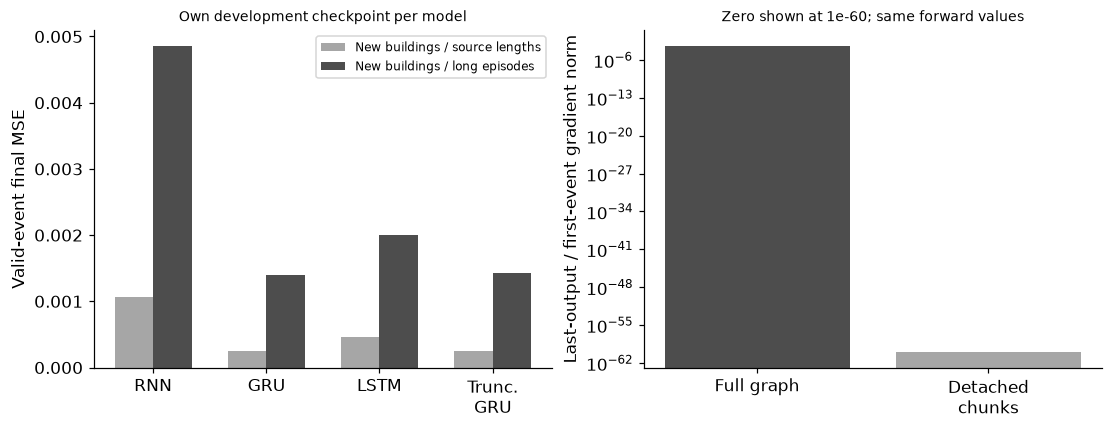

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,3.8));xx=np.arange(4)
axes[0].bar(xx-.17,[r['final_source_length_MSE'] for r in rows],.34,color='.65',label='New buildings / source lengths');axes[0].bar(xx+.17,[r['final_long_episode_MSE'] for r in rows],.34,color='.3',label='New buildings / long episodes');axes[0].set(xticks=xx,xticklabels=['RNN','GRU','LSTM','Trunc.\nGRU'],ylabel='Valid-event final MSE',title='Own development checkpoint per model');axes[0].legend(fontsize=8)
axes[1].bar([0,1],[max(full_first_gradient,1e-60),max(truncated_first_gradient,1e-60)],color=['.3','.65']);axes[1].set(yscale='log',xticks=[0,1],xticklabels=['Full graph','Detached\nchunks'],ylabel='Last-output / first-event gradient norm',title='Zero shown at 1e-60; same forward values');plt.show()
assert all(np.isfinite(r['final_long_episode_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_110','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual RNN GRU and LSTM', 'irregular-time input contract', 'masked losses', 'truncated derivative history', 'streaming state and entity resets'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual RNN GRU and LSTM", "irregular-time input contract", "masked losses", "truncated derivative history", "streaming state and entity resets"], "elapsed_seconds": 1.696, "example_id": "code_110", "hardware": "Darwin arm64 CPU", "results": {"GRU_first_reset_gate": [0.6053136634652837, 0.38309667689725446, 0.6175189817562359, 0.6527573383785739, 0.45112054381750555, 0.43438906563754104, 0.4032557216317348, 0.7653163247948293], "GRU_first_update_gate": [0.752554893149598, 0.7017785128434131, 0.5724813699752727, 0.3936913374969174, 0.5053694874328859, 0.6349769383593311, 0.7142826365323944, 0.48025907835608367], "comparisons": [{"best_update": 115, "development_MSE": 0.0013886447426676276, "final_long_episode_MSE": 0.00485013575605835, "final_source_length_MSE": 0.001067300937370796, "model": "RNN", "parameters": 113}, {"best_update": 120, "development_MSE": 0.0002969402235129684, "final_long_episode_MSE": 0.001395222197314509, "final_so